# XAI-IDS Robustness - Results Analysis

Evaluating the **tamper resistance** and **fragility** of SHAP and LIME explanations
in ML-based intrusion detection, across 2 datasets (CICIDS-2017, UNSW-NB15),
2 models (XGBoost, MLP), 2 explainers (SHAP, LIME), and 3 seeds.

| RQ | Question | Strand |
|---|---|---|
| **RQ1** | How do FGSM/PGD perturbations affect the stability, fidelity, and attribution drift of SHAP and LIME across varying attack intensities? | fragility |
| **RQ2** | Does model architecture (XGBoost vs MLP) moderate that adversarial robustness? | fragility |
| **RQ3** | Can a *targeted* attack alter SHAP/LIME while preserving the prediction, and does architecture moderate this tamper resistance? | tamper |

This notebook analyses the archived v1 record in `results/v1/results.csv`.
`xai-ids grid`) and recomputes every table, test, and figure below.

## Setup and data loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({"figure.dpi": 110})
COL = {"shap": "#E8833A", "lime": "#3A7BD5"}   # consistent explainer colours
pd.set_option("display.width", 160)

df = pd.read_csv("results/v1/results.csv")

# housekeeping: drop the one stale duplicate (old slug missing `method`) and the
# vestigial all-NaN `queries` column, so nothing double-counts.
df = df[df.experiment_id != "unsw-xgboost-shap-tamp-e0.03-s42"]
df = df.drop(columns=[c for c in ["queries"] if c in df.columns])

frag = df[df.strand == "fragility"].copy()
tamp = df[df.strand == "tamper"].copy()
print(f"rows: {len(df)}  |  fragility: {len(frag)}  |  tamper: {len(tamp)}")
df.head(3)

rows: 168  |  fragility: 144  |  tamper: 24


,experiment_id,dataset,model,explainer,strand,method,objective,gradient_source,epsilon,seed,...,spearman,topk_jaccard,fidelity_baseline_deletion,fidelity_adversarial_deletion,fidelity_baseline_insertion,fidelity_adversarial_insertion,tamper_success,n_perturbed,model_queries,explainer_calls
1,cicids-xgboost-shap-tamp-pgd-e0.03-s42,cicids2017,xgboost,shap,tamper,pgd,attribution,spsa,0.03,42,...,0.992765,0.992354,0.028077,0.027833,0.935857,0.930478,0.000,9,1570.0,201.0
2,cicids-xgboost-shap-tamp-pgd-e0.03-s7,cicids2017,xgboost,shap,tamper,pgd,attribution,spsa,0.03,7,...,0.994699,0.993678,0.029601,0.029728,0.930755,0.926594,0.002,7,1537.0,93.0
3,cicids-xgboost-shap-tamp-pgd-e0.03-s123,cicids2017,xgboost,shap,tamper,pgd,attribution,spsa,0.03,123,...,0.990737,0.989582,0.033034,0.033039,0.929675,0.923879,0.000,10,1530.0,33.0


### Coverage check
Expected: fragility = 2x2x2x2x3x3 = 144, tamper = 2x2x2x3 = 24.

In [2]:
print("cells with NaN drift (fragility):", int(frag.drift_cosine.isna().sum()))
print("fragility n_evaluated (min/median/max):",
      frag.n_evaluated.min(), int(frag.n_evaluated.median()), frag.n_evaluated.max())
(df.groupby(["strand","dataset","model","explainer"]).size()
   .rename("n_cells").reset_index())

cells with NaN drift (fragility): 0
fragility n_evaluated (min/median/max): 500 500 500


,strand,dataset,model,explainer,n_cells
0,fragility,cicids2017,mlp,lime,18
1,fragility,cicids2017,mlp,shap,18
2,fragility,cicids2017,xgboost,lime,18
3,fragility,cicids2017,xgboost,shap,18
4,fragility,unsw_nb15,mlp,lime,18
5,fragility,unsw_nb15,mlp,shap,18
6,fragility,unsw_nb15,xgboost,lime,18
7,fragility,unsw_nb15,xgboost,shap,18
8,tamper,cicids2017,mlp,lime,3
9,tamper,cicids2017,mlp,shap,3


## RQ3 - Tamper resistance (headline)

`tamper_success` = fraction of true-positive flows where the targeted SPSA attack
pushed the originally-decisive (top-1) feature out of the top-*k* attribution set
**while the model's prediction was held fixed**. Higher = easier to tamper = *less*
tamper-resistant.

In [3]:
tamp.groupby(["explainer","dataset","model"]).tamper_success.agg(["mean","std"]).round(3)

mean    std
explainer dataset    model                
lime      cicids2017 mlp      0.000  0.000
                     xgboost  0.087  0.040
          unsw_nb15  mlp      0.000  0.000
                     xgboost  0.000  0.000
shap      cicids2017 mlp      0.305  0.034
                     xgboost  0.001  0.001
          unsw_nb15  mlp      0.061  0.002
                     xgboost  0.283  0.167

In [4]:
pooled = tamp.groupby("explainer").tamper_success.agg(["mean","std","count"]).round(3)
print("Pooled tamper success by explainer:"); print(pooled)

s = tamp[tamp.explainer=="shap"].tamper_success.values
l = tamp[tamp.explainer=="lime"].tamper_success.values
U, pU = stats.mannwhitneyu(s, l, alternative="two-sided")
t, pt = stats.ttest_ind(s, l, equal_var=False)
gt = sum(x>y for x in s for y in l); lt = sum(x<y for x in s for y in l)
cliff = (gt-lt)/(len(s)*len(l))
print(f"\nMann-Whitney U={U:.1f}, p={pU:.4f}")
print(f"Welch t={t:.2f}, p={pt:.4f}")
print(f"Cliff's delta={cliff:.3f}  (|d|>0.47 = large effect)")

Pooled tamper success by explainer:
            mean    std  count
explainer                     
lime       0.022  0.043     12
shap       0.162  0.157     12

Mann-Whitney U=120.0, p=0.0039
Welch t=2.99, p=0.0108
Cliff's delta=0.667  (|d|>0.47 = large effect)


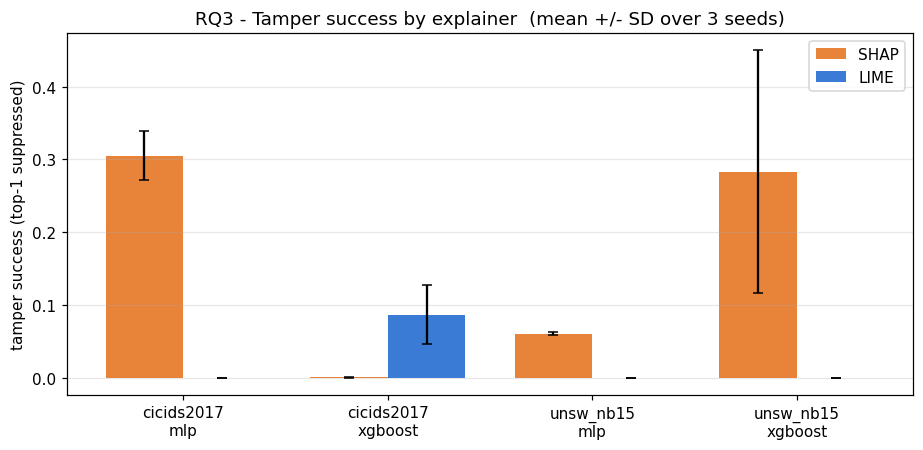

In [5]:
g = tamp.groupby(["dataset","model","explainer"]).tamper_success.mean().unstack("explainer")
gerr = tamp.groupby(["dataset","model","explainer"]).tamper_success.std().unstack("explainer")
labels = ["\n".join(ix) for ix in g.index]
x = np.arange(len(labels)); w = 0.38
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.bar(x-w/2, g["shap"], w, yerr=gerr["shap"], capsize=3, color=COL["shap"], label="SHAP")
ax.bar(x+w/2, g["lime"], w, yerr=gerr["lime"], capsize=3, color=COL["lime"], label="LIME")
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_ylabel("tamper success (top-1 suppressed)")
ax.set_title("RQ3 - Tamper success by explainer  (mean +/- SD over 3 seeds)")
ax.legend(); ax.grid(axis="y", alpha=0.3); fig.tight_layout(); plt.show()

## RQ1 - Fragility: stability, fidelity, and drift across attack intensities

`drift_cosine` = 1 - cosine similarity between baseline and post-attack attributions
(0 = unchanged, higher = more drift). `drift_cosine_adj` subtracts each explainer's
own **noise floor** (re-explaining the unperturbed input), isolating attack-induced
drift from intrinsic sampling noise.

In [6]:
frag.groupby("explainer")[["drift_cosine","drift_cosine_adj","spearman","topk_jaccard"]].mean().round(3)

,drift_cosine,drift_cosine_adj,spearman,topk_jaccard
explainer,,,,
lime,0.049,0.006,0.438,0.401
shap,0.610,0.452,0.346,0.316


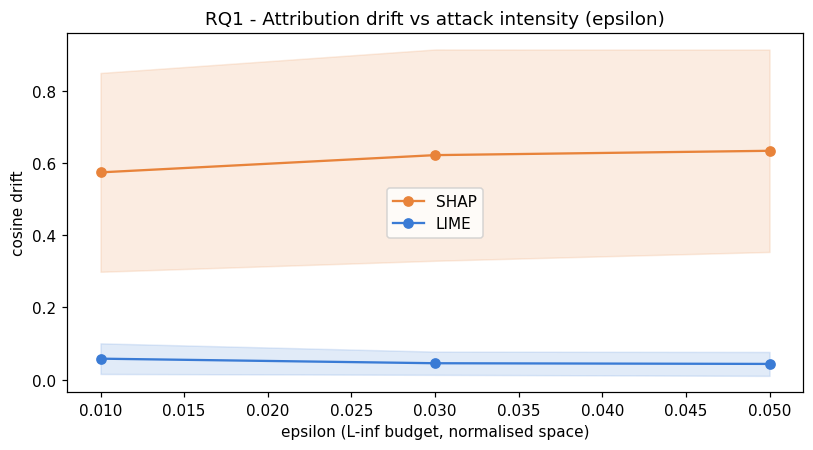

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for ex in ["shap","lime"]:
    d = frag[frag.explainer==ex].groupby("epsilon").drift_cosine.agg(["mean","std"])
    ax.plot(d.index, d["mean"], "-o", color=COL[ex], label=ex.upper())
    ax.fill_between(d.index, d["mean"]-d["std"], d["mean"]+d["std"], color=COL[ex], alpha=0.15)
ax.set_xlabel("epsilon (L-inf budget, normalised space)")
ax.set_ylabel("cosine drift")
ax.set_title("RQ1 - Attribution drift vs attack intensity (epsilon)")
ax.legend(); fig.tight_layout(); plt.show()

## RQ2 - Does model architecture moderate robustness?

XGBoost (TreeSHAP / LIME) vs MLP (KernelSHAP / LIME). The SHAP rows also change
*backend* with the model, so this comparison is architecture **and** backend -- see
caveats.

                   drift_cosine  spearman  topk_jaccard
explainer model                                        
lime      mlp             0.042     0.729         0.598
          xgboost         0.056     0.147         0.203
shap      mlp             0.376     0.290         0.215
          xgboost         0.843     0.402         0.418


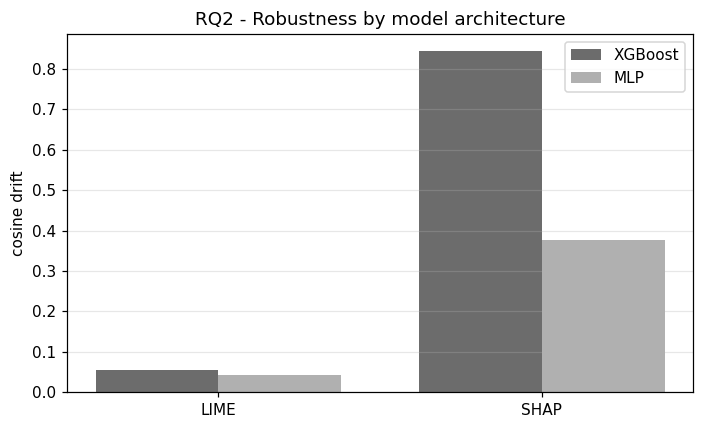

In [8]:
arch = frag.groupby(["explainer","model"])[["drift_cosine","spearman","topk_jaccard"]].mean().round(3)
print(arch)
piv = frag.groupby(["explainer","model"]).drift_cosine.mean().unstack("model")
x = np.arange(len(piv.index)); w = 0.38
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.bar(x-w/2, piv["xgboost"], w, color="#6C6C6C", label="XGBoost")
ax.bar(x+w/2, piv["mlp"], w, color="#B0B0B0", label="MLP")
ax.set_xticks(x); ax.set_xticklabels([e.upper() for e in piv.index])
ax.set_ylabel("cosine drift"); ax.set_title("RQ2 - Robustness by model architecture")
ax.legend(); ax.grid(axis="y", alpha=0.3); fig.tight_layout(); plt.show()

## Stability and fidelity (supporting RQ1)

**Stability** -- Spearman rank correlation and top-*k* Jaccard between baseline and
adversarial attributions (higher = more stable). **Fidelity** -- deletion AUC on
baseline vs adversarial explanations; a large baseline->adversarial change means the
attack degraded how faithfully the explanation tracks the model.

In [9]:
stab = frag.groupby("explainer")[["spearman","topk_jaccard"]].mean().round(3)
fid = df.groupby(["strand","explainer"])[["fidelity_baseline_deletion",
        "fidelity_adversarial_deletion","fidelity_baseline_insertion",
        "fidelity_adversarial_insertion"]].mean().round(3)
print("Stability (fragility):"); print(stab)
print("\nFidelity (deletion/insertion, baseline vs adversarial):"); print(fid)

Stability (fragility):
           spearman  topk_jaccard
explainer                        
lime          0.438         0.401
shap          0.346         0.316

Fidelity (deletion/insertion, baseline vs adversarial):
                     fidelity_baseline_deletion  fidelity_adversarial_deletion  fidelity_baseline_insertion  fidelity_adversarial_insertion
strand    explainer                                                                                                                        
fragility lime                            0.775                          0.672                        0.833                           0.586
          shap                            0.626                          0.619                        0.939                           0.582
tamper    lime                            0.775                          0.781                        0.833                           0.828
          shap                            0.626                          0.631      

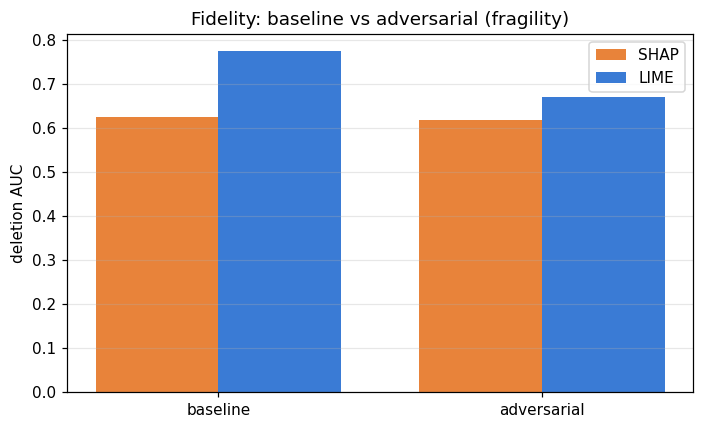

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 4))
x = np.arange(2); w = 0.38
for i, ex in enumerate(["shap","lime"]):
    d = frag[frag.explainer==ex]
    vals = [d.fidelity_baseline_deletion.mean(), d.fidelity_adversarial_deletion.mean()]
    ax.bar(x + (i-0.5)*w, vals, w, color=COL[ex], label=ex.upper())
ax.set_xticks(x); ax.set_xticklabels(["baseline","adversarial"])
ax.set_ylabel("deletion AUC"); ax.set_title("Fidelity: baseline vs adversarial (fragility)")
ax.legend(); ax.grid(axis="y", alpha=0.3); fig.tight_layout(); plt.show()

## Findings and honest caveats

**Findings**

1. **RQ3 (headline):** SHAP is significantly more *tamperable* than LIME under the
   targeted SPSA attack (mean 0.16 vs 0.02; Mann-Whitney *p* ~ 0.004, Cliff's delta ~ 0.67,
   a large effect). Softest targets: SHAP on the CICIDS MLP and SHAP on UNSW XGBoost.
2. **RQ1:** The same ordering holds, more strongly, for *incidental* fragility --
   SHAP drifts an order of magnitude more than LIME (0.61 vs 0.05 cosine; 0.45 vs
   0.006 after noise-floor subtraction), and SHAP drift grows with the attack budget.
3. **RQ2:** Architecture interacts with the explainer: for SHAP the XGBoost/TreeSHAP
   pairing drifts more than MLP/KernelSHAP, while for LIME rank stability collapses
   on XGBoost (Spearman 0.15 vs 0.73 on MLP).

**Caveats (carry into the write-up)**

- **Small, non-independent n.** 3 seeds x 4 (dataset x model) cells per explainer; the
  cells share datasets/models, so the significance test is *suggestive*, not definitive.
- **LIME's low scores are ambiguous.** LIME's near-zero drift/tamper partly reflects
  that its stochastic **noise floor swamps the attack signal** -- "hard to attack
  reliably" is not the same as "deeply robust."
- **Backend confound.** SHAP uses exact TreeSHAP on XGBoost but approximate KernelSHAP
  on the MLP, so the architecture comparison mixes architecture with SHAP backend.
- **Normalised-space epsilon.** Epsilon is comparable *within* but not *across* datasets.